## DS2023 Project 2

### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from ipywidgets import interact

### Load Data

In [3]:
#Loading in data
#Check for missing values is in looking_at_data_options.ipynb


living_cases = pd.read_csv("persons-living-with-hiv-aids.csv")
new_cases = pd.read_csv("persons-newly-diagnosed-with-hiv.csv")
deaths = pd.read_csv("deaths-of-persons-diagnosed-with-hiv-aids.csv")

# Combine the CSVs without error
# Solution provided by Prof. Alvarado

'''It turns out that each table had two different category names, corresponding to their unit of observation.
So, [Prof. Alvarado] just changed them, but the user should know what 'Age' and 'City' actually mean when viewing results.'''

key = ['Year', 'Category', 'Group']

df1 = living_cases.rename(columns={'Count': 'Count_Living'})
df1['Category'] = df1['Category'].replace({'Age at Year End (in years)':'Age', 'City of Current Residence':'City', 'County of Current Residence':'County'})
df1 = df1.set_index(key)

df2 = new_cases.rename(columns={'Count': 'Count_New'})
df2['Category'] = df2['Category'].replace({'Age at Diagnosis (in years)':'Age', 'City of Residence at Diagnosis':'City', 'County of Residence at Diagnosis':'County'})
df2 = df2.set_index(key)

df3 = deaths.rename(columns={'Count': 'Count_Deaths'})
df3['Category'] = df3['Category'].replace({'Age at Death (in years)':'Age', 'City of Residence at Death':'City', 'County of Residence at Death':'County'})
df3 = df3.set_index(key)

hiv_aids = df1.join(df2).join(df3)

hiv_aids.head()

Count_Living  Count_New  Count_Deaths
Year Category Group                                          
2010 Age      0 to 11            174       16.0             1
              12 to 14           112        3.0             0
              15 to 17           206       30.0             1
              18 to 19           345      131.0             1
              20 to 24          3001      780.0            15

In [4]:
#back to regular columns so the keys are available for plotting and grouping
hiv_aids = hiv_aids.reset_index()
hiv_aids.head()
hiv_aids.info()


<class 'pandas.DataFrame'>
RangeIndex: 1722 entries, 0 to 1721
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Year          1722 non-null   int64  
 1   Category      1722 non-null   str    
 2   Group         1722 non-null   str    
 3   Count_Living  1722 non-null   int64  
 4   Count_New     1721 non-null   float64
 5   Count_Deaths  1722 non-null   int64  
dtypes: float64(1), int64(3), str(2)
memory usage: 80.8 KB


In [18]:
#adding analytical columns (rates per 10,000 people)
#rates per 1,000 people living with HIV, so groups of different sizes are comparable
hiv_aids['Death_Rate'] = hiv_aids.Count_Deaths / hiv_aids.Count_Living * 1000
hiv_aids['Diagnosis_Rate'] = hiv_aids.Count_New / hiv_aids.Count_Living * 1000

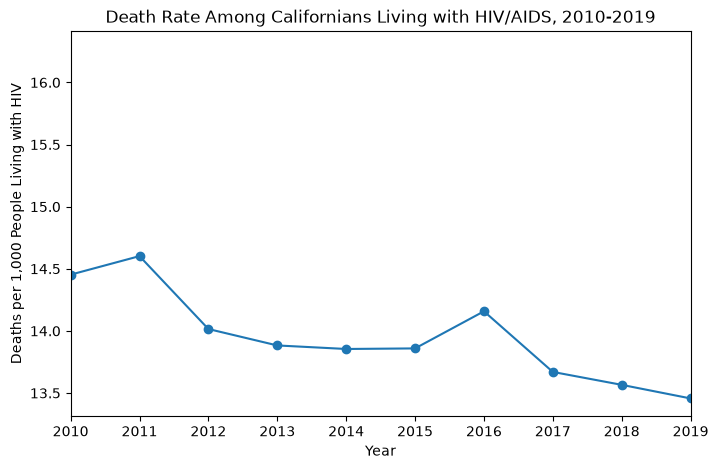

In [ ]:
#computing death rate over time by year
by_year = hiv_aids[hiv_aids.Category == 'Race/Ethnicity'].groupby('Year')[['Count_Living','Count_Deaths']].sum() #using one category to avoid double counting, since the same person can be counted in multiple categories
death_rate_over_time = by_year.Count_Deaths / by_year.Count_Living * 1000

ax = death_rate_over_time.plot.line(marker='o', figsize=(8,5))
ax.set_xlabel('Year')
ax.set_xlim(2010, 2019)
ax.set_ylabel('Deaths per 1,000 People Living with HIV')
ax.set_title('Death Rate Among Californians Living with HIV/AIDS, 2010-2019')
plt.show()

#could maybe annotate the graph with a line of overall california death rate